
# Topic 5: Wiener Processes and Stochastic Differential Equations

**Core Question:** How can we construct a continuous-time random process and use it to simulate financial asset prices?

### Overview

In Topic 4, we simulated Geometric Brownian Motion (GBM) on a fixed time grid using independent normal shocks.

However, simulating a new path on a finer grid does not preserve the original simulated values.

This motivates the construction of a **Wiener process (standard Brownian motion)**, which provides the mathematical foundation for continuous-time stochastic modelling.

We will first simulate Wiener paths, then refine them using Brownian bridges, before applying the process to stochastic differential equations (SDEs).

### Learning Roadmap

1. **Wiener Process:** Understand independent Gaussian increments and continuous sample paths.
2. **Path Simulation:** Construct Wiener paths using discrete normal increments.
3. **Brownian Bridge:** Refine an existing path while preserving previously simulated values.
4. **Unit Testing:** Verify deterministic functions and the statistical properties of simulated paths.
5. **Self-Similarity:** Explore Brownian scaling and the roughness of Wiener paths.
6. **SDEs:** Extend deterministic differential equations by introducing random fluctuations.
7. **Euler–Maruyama:** Simulate stock price dynamics using Wiener increments.

### Core Connections

$$
\text{Independent Normal Increments}
\longrightarrow \text{Wiener Process}
$$

$$
\text{Wiener Process}
\longrightarrow \text{Brownian Bridge Refinement}
$$

$$
\text{Wiener Process}+\text{Drift}
\longrightarrow \text{Stochastic Differential Equations}
$$

**Financial Motivation:** Wiener processes provide the source of randomness in continuous-time financial models, including Geometric Brownian Motion.



## 1. Wiener Process and Simulation

### 1.1 Definition of a Wiener Process

A **Wiener process** $W_t$ is a continuous-time stochastic process satisfying four properties:

- **Initial value:** $W_0=0$.
- **Independent increments:** Increments over disjoint time intervals are independent.
- **Normal increments:** For any $t>s$,

$$
W_t-W_s\sim N(0,t-s)
$$

- **Continuous paths:** Sample paths are continuous almost surely.

### 1.2 Statistical Properties

Since $W_t=W_t-W_0$,

$$
E[W_t]=0,\qquad \operatorname{Var}(W_t)=t
$$

For $s\leq t$, write:

$$
W_t=W_s+(W_t-W_s)
$$

Using the independence of increments,

$$
\begin{aligned}
\operatorname{Cov}(W_s,W_t)
&=\operatorname{Cov}(W_s,W_s+(W_t-W_s))\\
&=\operatorname{Var}(W_s)\\
&=s
\end{aligned}
$$

Therefore,

$$
\boxed{\operatorname{Cov}(W_s,W_t)=\min(s,t)}
$$

**Important:** Independent increments do not imply independent process values.

### 1.3 Simulating Wiener Paths

Divide $[0,T]$ into $n$ intervals of equal length:

$$
\Delta t=\frac{T}{n}
$$

A Wiener increment is simulated as:

$$
\Delta W_i=\sqrt{\Delta t}\,\epsilon_i,
\qquad \epsilon_i\overset{iid}{\sim}N(0,1)
$$

The recursive simulation is:

$$
\boxed{W_{t_{i+1}}=W_{t_i}+\sqrt{\Delta t}\,\epsilon_i}
$$

### Python Implementation

- `one_step_wiener()` generates the initial and terminal values of a one-step Wiener path.
- `simulate_wiener_paths()` generates multiple paths using independent normal increments.
- `np.sqrt(dt)` ensures that the increment variance equals the elapsed time.
- Each path is constructed by accumulating the simulated increments.

**Interpretation:** The simulated paths fluctuate randomly around zero. Increasing the number of time steps reveals finer details of the process.


In [29]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

def one_step_wiener(T, rng=None):
    if T <= 0:
        raise ValueError("T must be positive.")
    
    rng = rng if rng is not None else np.random.default_rng()

    times = np.array([0, T])
    W = np.zeros(2)

    epsilon = rng.standard_normal()

    W[1] = W[0] + np.sqrt(T) * epsilon

    return W, times
    
def simulate_wiener_paths(T, n_paths, n_steps):   # n = number of intervals, therefore there are n+1 time points
    times = np.linspace(0, T, n_steps + 1)
    dt = T/ n_steps
    epsilon = rng.standard_normal((n_paths, n_steps))
    dW = np.sqrt(dt) * epsilon
    W = np.zeros((n_paths, n_steps + 1))
    
    for i in range(n_steps):
        W[:, i+1] = W[:, i] + dW[:, i]
    
    return W, times


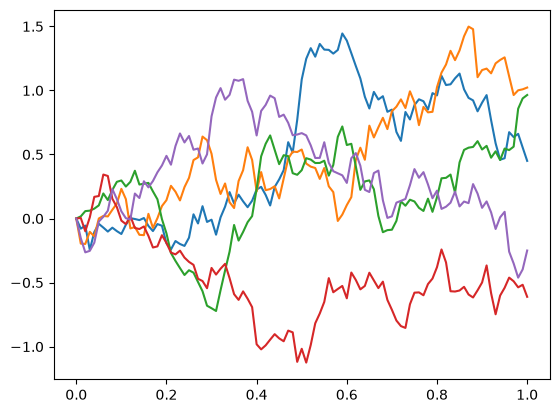

In [30]:
W, times = simulate_wiener_paths(1, 5, 100)

plt.plot(times, W.T)
plt.show()


## 2. Brownian Bridge Construction

### 2.1 Why Do We Need a Brownian Bridge?

A fixed-grid simulation generates Wiener values sequentially using independent normal increments.

However, generating a new simulation with a smaller time step produces a different random path.

**Goal:** Add new intermediate points to an existing Wiener path without changing its previously simulated values.

This is achieved through **Brownian bridge construction**.

### 2.2 Conditional Midpoint Distribution

Consider an interval $[a,b]$, with midpoint:

$$
m=\frac{a+b}{2}
$$

Suppose the Wiener process values at both endpoints are known:

$$
W_a=w_a,\qquad W_b=w_b
$$

The conditional distribution of the midpoint is:

$$
\boxed{
W_m\mid(W_a=w_a,W_b=w_b)
\sim N\left(
\frac{w_a+w_b}{2},
\frac{b-a}{4}
\right)
}
$$

Therefore, we simulate the midpoint using:

$$
\boxed{
W_m=
\frac{w_a+w_b}{2}
+\frac{\sqrt{b-a}}{2}\epsilon
}
$$

where $\epsilon\sim N(0,1)$ is a fresh independent standard normal variable.

### 2.3 Mathematical Intuition

The simulated midpoint contains two components:

**Conditional mean:**

$$
E[W_m\mid W_a,W_b]=\frac{W_a+W_b}{2}
$$

**Conditional variance:**

$$
\operatorname{Var}(W_m\mid W_a,W_b)=\frac{b-a}{4}
$$

Knowing both endpoints reduces uncertainty about the midpoint, but the midpoint remains random.

This formula follows from the joint multivariate normal distribution of Wiener values, using the covariance structure from Topic 3.

### 2.4 Python Implementation

The construction is divided into four functions:

- `compute_halfway_times(t)` calculates the midpoint of each time interval.
- `riffle(v1, v2)` interleaves old and newly simulated values.
- `simulate_intermediate_values(W, t, rng)` generates midpoint values using the Brownian bridge formula.
- `wiener_interpolate(W, t, rng)` combines the functions to produce a refined Wiener path.

**Key Property:** Existing Wiener values remain unchanged, while new midpoint values are sampled conditionally on the endpoints.

After $k$ refinements of one interval, the resulting grid contains $2^k$ intervals and $2^k+1$ time points.


In [31]:
def compute_halfway_times(t):
    return 1/2 * (t[:-1] + t[1: ])


def riffle(v1, v2):
    # Interleave original values and midpoints while preserving the original values
    assert len(v1) == len(v2) + 1

    result = np.zeros(len(v1) + len(v2))
    result[::2] = v1
    result[1::2] = v2

    return result


def simulate_intermediate_values(W, t, rng=None):
    rng = rng if rng is not None else np.random.default_rng()

    dt = np.diff(t)
    epsilon = rng.standard_normal(len(dt))

    W_mids = 0.5 * (W[:-1] + W[1:]) + 0.5 * np.sqrt(dt) * epsilon

    return W_mids

def wiener_interpolate(W, t, rng):
    times = riffle(t, compute_halfway_times(t))
    W = riffle(W, simulate_intermediate_values(W, t, rng))
    
    return W, times


In [32]:
# Test
W, t = one_step_wiener(1, rng)

W, t = wiener_interpolate(W, t, rng)
W, t = wiener_interpolate(W, t, rng)

print("Times:", t)
print("Wiener values:", W)

Times: [0.   0.25 0.5  0.75 1.  ]
Wiener values: [0.         0.30356166 1.38212067 1.32015284 2.05811529]



## 3. Unit Testing for Stochastic Simulations

### 3.1 Why Do We Need Unit Testing?

Numerical simulations involve both deterministic calculations and random sampling.

Unit tests help verify whether the implementation satisfies the mathematical properties of the model.

There are two main types of tests:

- **Deterministic tests:** Compare outputs against exactly specified results.
- **Statistical tests:** Compare empirical moments against theoretical values using numerical tolerances.

### 3.2 Testing Deterministic Functions

The functions `compute_halfway_times()` and `riffle()` have predictable outputs.

We use:

`np.testing.assert_allclose()`

to verify that the calculated arrays match the expected values within a specified tolerance.

### 3.3 Testing Wiener Increments

For a Wiener process on $[0,1]$, define:

$$
D_1=W_{1/2}-W_0
$$

$$
D_2=W_1-W_{1/2}
$$

By the independent increment property:

$$
E[D_1]=E[D_2]=0
$$

$$
\operatorname{Var}(D_1)
=\operatorname{Var}(D_2)=\frac12
$$

$$
\operatorname{Cov}(D_1,D_2)=0
$$

Therefore, the theoretical covariance matrix is:

$$
\boxed{
\Sigma_D=
\begin{pmatrix}
1/2&0\\
0&1/2
\end{pmatrix}
}
$$

The function `test_simulate_intermediate_values()` generates many simulations and checks whether the sample mean and covariance are close to these theoretical values.

### 3.4 Testing Path Refinement

The function `test_wiener_interpolate()` checks two important properties.

**Preservation of existing values:**

The original time points and Wiener values must remain unchanged after refinement.

**Correct covariance structure:**

For the refined grid with times $1/4,1/2,3/4,1$, the covariance matrix follows:

$$
\operatorname{Cov}(W_s,W_t)=\min(s,t)
$$

This gives:

$$
\Sigma=
\begin{pmatrix}
1/4&1/4&1/4&1/4\\
1/4&1/2&1/2&1/2\\
1/4&1/2&3/4&3/4\\
1/4&1/2&3/4&1
\end{pmatrix}
$$

**Interpretation:** The tests provide evidence that midpoint refinement preserves both the existing path values and the required Wiener covariance structure.

Because the tests use finite random samples, small deviations from theoretical moments are expected.


In [33]:
def test_compute_halfway_times():
    test_t = np.array([0, 1/4, 1/2, 3/4, 1])
    actual = compute_halfway_times(test_t)
    expected = np.array([1/8, 3/8, 5/8, 7/8])
    
    assert actual.shape == expected.shape
    np.testing.assert_allclose(actual, expected, atol= 1e-12, rtol=0)

test_compute_halfway_times()

def test_riffle():
    test_v1 = np.array([0, 1, 2])
    test_v2 = np.array([0.5, 1.5])
    actual = riffle(test_v1, test_v2)
    expected = np.array([0, 0.5, 1, 1.5, 2])

    assert actual.shape == expected.shape
    np.testing.assert_allclose(actual, expected, atol= 1e-12, rtol=0)

test_riffle()

def test_simulate_intermediate_values(n=10000):
    samples = np.zeros((n, 2))
    
    for i in range(len(samples)):
        W, t = one_step_wiener(1, rng)

        W_half = simulate_intermediate_values(W, t, rng)[0]

        samples[i] = [W_half - W[0], W[1] - W_half]

    sample_mean = np.mean(samples, axis=0)
    sample_cov = np.cov(samples, rowvar=False)

    expected_mean = np.zeros(2)
    expected_cov = np.eye(2) * 0.5

    np.testing.assert_allclose(sample_mean, expected_mean, rtol=0, atol = 0.04)
    np.testing.assert_allclose(sample_cov, expected_cov, rtol=0, atol = 0.04)

test_simulate_intermediate_values()


def test_wiener_interpolate(n=10000):
    samples = np.zeros((n, 4))

    for i in range(n):
        W, t = one_step_wiener(1, rng)
        
        W_old, t_old = wiener_interpolate(W, t, rng)

        W_new, t_new = wiener_interpolate(W_old, t_old, rng)

        np.testing.assert_array_equal(W_old, W_new[::2])
        np.testing.assert_array_equal(t_old, t_new[::2])

        samples[i] = W_new[1:]

    samples_mean = np.mean(samples, axis=0)
    samples_cov = np.cov(samples, rowvar=False)

    expected_mean = np.zeros(4)
    expected_cov = np.array([
        [1/4, 1/4, 1/4, 1/4],
        [1/4, 1/2, 1/2, 1/2],
        [1/4, 1/2, 3/4, 3/4],
        [1/4, 1/2, 3/4, 1]
    ])

    np.testing.assert_allclose(
        samples_mean, expected_mean, rtol=0, atol=0.04
    )

    np.testing.assert_allclose(
        samples_cov, expected_cov, rtol=0, atol=0.05
    )

test_wiener_interpolate()


## 4. Brownian Scaling and Self-Similarity

### 4.1 Brownian Scaling Property

A Wiener process has the property of **self-similarity**.

For any constant $c>0$, define:

$$
\widetilde W_t=\frac{W_{ct}}{\sqrt c}
$$

The rescaled process has the same distribution as the original standard Wiener process:

$$
\boxed{
(\widetilde W_t)_{t\geq0}
\overset{d}{=}(W_t)_{t\geq0}
}
$$

### 4.2 Why Is the Scaling Factor a Square Root?

For a Wiener increment:

$$
\operatorname{Var}(W_{ct}-W_{cs})=c(t-s)
$$

Dividing by $\sqrt c$ gives:

$$
\operatorname{Var}\left(
\frac{W_{ct}-W_{cs}}{\sqrt c}
\right)=t-s
$$

Thus the rescaled process has the correct Wiener increment variance.

### 4.3 Zooming into the Central Half

To visualise this property, consider the central interval:

$$
[1/4,3/4]
$$

Its duration is $1/2$.

To rescale the interval to unit length, we multiply the Wiener fluctuations by:

$$
\frac{1}{\sqrt{1/2}}=\sqrt2
$$

The function `zoom()` performs three operations:

1. Refines the existing Wiener path.
2. Extracts its central half.
3. Rescales the path values by $\sqrt2$ and shifts them vertically.

### Python Visualisation

- `zoom_plot()` identifies and highlights the central interval.
- `zoom()` refines the path and extracts the rescaled middle segment.
- The final plot compares the original path with its zoomed segment.

**Interpretation:** Even when we zoom into a small interval, the Wiener path continues to display irregular fluctuations.

A Wiener path is continuous almost surely, but nowhere differentiable almost surely.

**Note:** The midpoint-centred zoom visualises local fluctuations; its starting value is not necessarily zero, so the displayed segment is not generally a standard Wiener process starting at zero.


In [34]:
def zoom_plot(W, t):
    n = len(t) - 1
    midpoint = W[n // 2]
    ax = plt.gca()
    ax.plot(t, W)

    left, right = 0.25, 0.75
    bottom, top = midpoint - 1, midpoint + 1

    ax.plot(
        [left, left, right, right, left],
        [top, bottom, bottom, top, top]
    )

    ax.set_xlabel("Rescaled time")
    ax.set_ylabel("Rescaled Wiener value")

    return midpoint

def zoom(W, t, rng=None):
    n = len(t) - 1

    if len(W) != len(t) or n < 2 or n % 2:
        raise ValueError(
            "Use matching vectors with an even number of intervals."
        )

    np.testing.assert_allclose(t, np.linspace(0, 1, n + 1))

    midpoint = zoom_plot(W, t)

    refined_W, refined_t = wiener_interpolate(W, t, rng)

    middle = refined_W[n // 2 : 3 * n // 2 + 1]

    return np.sqrt(2) * (middle - midpoint), t.copy()

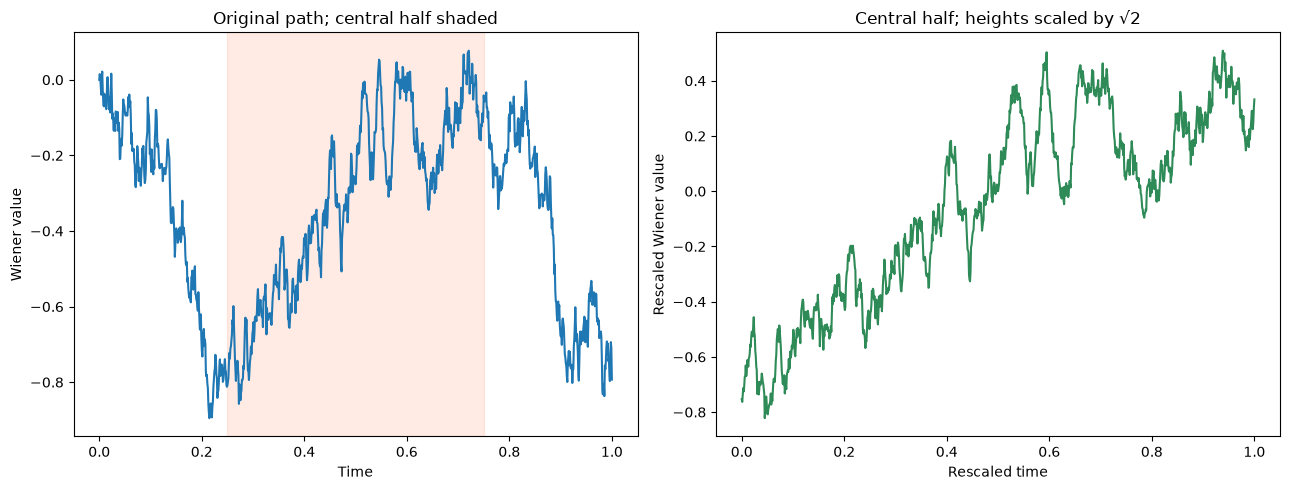

In [35]:
rng = np.random.default_rng(2026)

# Generate and refine Wiener path
W, t = one_step_wiener(1, rng)

for i in range(10):
    W, t = wiener_interpolate(W, t, rng)

# Generate the zoomed path
# zoom() also creates its own plot, which we close here
W_zoom, t_zoom = zoom(W, t, rng)
plt.close()

# Create two subplots side by side
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Left: original Wiener path
axs[0].plot(t, W, label="Original Wiener path")
axs[0].axvspan(0.25, 0.75, color="coral", alpha=0.15)
axs[0].set_title("Original path; central half shaded")
axs[0].set_xlabel("Time")
axs[0].set_ylabel("Wiener value")

# Right: zoomed Wiener path
axs[1].plot(t_zoom, W_zoom, color="seagreen")
axs[1].set_title("Central half; heights scaled by √2")
axs[1].set_xlabel("Rescaled time")
axs[1].set_ylabel("Rescaled Wiener value")

plt.tight_layout()
plt.show()


## 5. Stochastic Differential Equations

### 5.1 From ODEs to SDEs

An **Ordinary Differential Equation (ODE)** describes deterministic change:

$$
\frac{dy(t)}{dt}=f(y(t),t)
$$

Its integral representation is:

$$
y(t)=y(0)+\int_0^t f(y(s),s)\,ds
$$

Using the Euler method, we approximate the solution by:

$$
y_{i+1}=y_i+f(y_i,t_i)\Delta t
$$

However, financial asset prices are affected by both systematic changes and random market fluctuations.

We therefore introduce a Wiener process to model randomness.

### 5.2 General Form of an SDE

A one-dimensional SDE can be written as:

$$
\boxed{
dY_t=a(Y_t,t)\,dt+b(Y_t,t)\,dW_t
}
$$

where:

- $a(Y_t,t)$ is the **drift coefficient**, describing systematic change.
- $b(Y_t,t)$ is the **diffusion coefficient**, controlling random fluctuations.
- $W_t$ is a standard Wiener process.

### 5.3 Euler–Maruyama Approximation

The Euler–Maruyama method extends the deterministic Euler method by introducing Wiener increments.

$$
\boxed{
Y_{i+1}
=Y_i+a(Y_i,t_i)\Delta t+b(Y_i,t_i)\Delta W_i
}
$$

where:

$$
\Delta W_i=\sqrt{\Delta t}\,\epsilon_i
$$

**Key Idea:**

$$
\text{New Value}
=\text{Current Value}
+\text{Drift}
+\text{Random Fluctuation}
$$

### 5.4 Application to Geometric Brownian Motion

For continuous-time GBM:

$$
\boxed{
dS_t=\mu S_t\,dt+\sigma S_t\,dW_t
}
$$

The Euler–Maruyama update becomes:

$$
\boxed{
S_{i+1}
=S_i+\mu S_i\Delta t+\sigma S_i\Delta W_i
}
$$

The function `simulate_S()` implements this approximation using the simulated Wiener path.

**Interpretation:** The drift determines the systematic component of stock price movements, while the diffusion term introduces random fluctuations proportional to the current stock price.


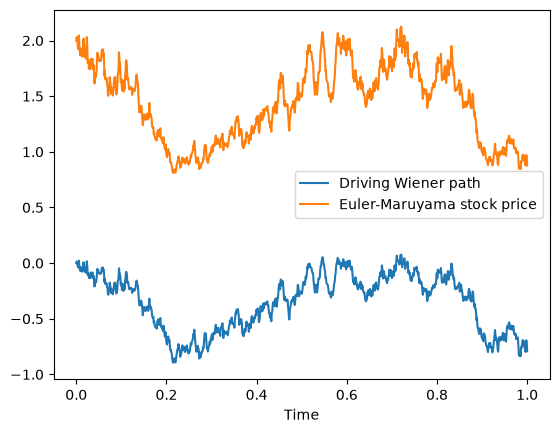

In [36]:
def simulate_S(S0, mu, sigma, W, t):
    delta_W = W[1:] - W[:-1]
    delta_t = t[1:] - t[:-1]
    S = np.zeros(len(t))
    S[0] = S0
    for i in range(len(t) - 1):
        S[i+1] = S[i] + mu * S[i] * delta_t[i] + sigma * S[i] * delta_W[i]
    return S

S0, mu, sigma = 2, 0.5, 1 
S = simulate_S(S0, mu, sigma, W, t) 
plt.figure() 
plt.plot(t, W, label="Driving Wiener path") 
plt.plot(t, S, label="Euler-Maruyama stock price") 
plt.xlabel("Time") 
plt.legend()

# Wiener Randomness + Positive Drift --> Stock Price Dynamics


## 6. Refining the Euler–Maruyama Approximation

### 6.1 Motivation

Euler–Maruyama provides an approximate solution to an SDE.

The numerical approximation depends on the chosen time-step size:

$$
\Delta t=\frac{T}{n}
$$

To investigate numerical accuracy, we compare approximations using different time grids.

### 6.2 Exact Solution of GBM

The exact solution of continuous-time GBM is:

$$
\boxed{
S_t=S_0\exp\left[
\left(\mu-\frac12\sigma^2\right)t+\sigma W_t
\right]
}
$$

The exponential form guarantees that $S_t>0$ whenever $S_0>0$.

In contrast, a coarse Euler–Maruyama approximation may produce negative simulated prices.

### 6.3 Why Preserve the Same Wiener Path?

When changing the time grid, generating a completely new Wiener path would introduce additional randomness.

This would make it difficult to distinguish numerical approximation error from differences between random paths.

Brownian bridge refinement solves this problem by preserving existing Wiener values while adding new intermediate points.

### Python Implementation

The function `next_plot()`:

1. Computes the Euler–Maruyama approximation for the current time grid.
2. Plots the underlying Wiener path and simulated stock price.
3. Refines the Wiener path for the next simulation.

**Interpretation:** Refining the time grid allows us to investigate how the numerical approximation changes while using a consistent underlying source of randomness.

Under suitable regularity assumptions, Euler–Maruyama approximations converge to the SDE solution as the time step approaches zero.

**Important:** Numerical errors do not necessarily decrease at every individual refinement.


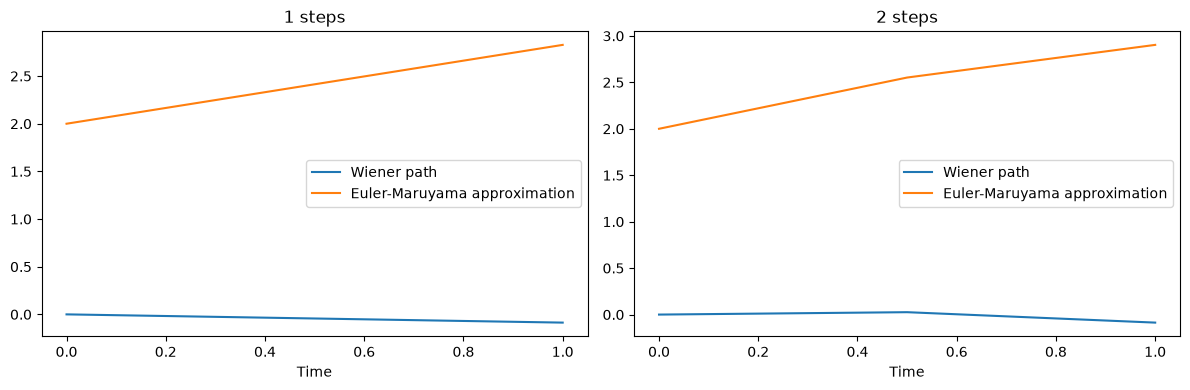

In [37]:
def next_plot(W, t, ax):
    S = simulate_S(S0, mu, sigma, W, t)

    ax.plot(t, W, label="Wiener path")
    ax.plot(t, S, label="Euler-Maruyama approximation")
    ax.set_title(f"{len(t) - 1} steps")
    ax.set_xlabel("Time")
    ax.legend()

    return wiener_interpolate(W, t, rng)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

W_coarse, t_coarse = one_step_wiener(1, rng)

W_coarse, t_coarse = next_plot(W_coarse, t_coarse, axs[0])

W_coarse, t_coarse = next_plot(W_coarse, t_coarse, axs[1])

plt.tight_layout()
plt.show()


## Key Takeaways

### Wiener Processes

- A Wiener process has independent Gaussian increments with variance equal to elapsed time.
- Wiener values are generally dependent, with covariance $\operatorname{Cov}(W_s,W_t)=\min(s,t)$.
- Paths are continuous but almost surely nowhere differentiable.

### Brownian Bridge

- Midpoint refinement preserves existing simulated values.
- The midpoint follows a conditional normal distribution determined by the two endpoints.
- Brownian bridge construction enables consistent simulation across increasingly fine time grids.

### Numerical Implementation

- Unit tests check deterministic outputs and statistical properties of simulated processes.
- Brownian scaling demonstrates the self-similarity of Wiener fluctuations.
- Euler–Maruyama approximates SDEs using drift and Wiener increments.

### Financial Application

- Continuous-time GBM models stock prices using proportional drift and diffusion.
- The exact GBM solution is exponential and always positive.
- Euler–Maruyama approximations converge under suitable conditions as the time grid becomes finer.

### Connection to Previous Topics

- **Topic 3:** Multivariate normal distributions and covariance matrices explain Brownian bridge construction.
- **Topic 4:** Discrete-time GBM connects naturally to continuous-time stochastic differential equations.

**Overall:** Wiener processes provide the mathematical foundation for continuous-time stochastic modelling, while Brownian bridge refinement and Euler–Maruyama provide practical numerical tools for financial simulations.
